In [1]:
# ============================================================
# RISKWEAVE - NOTEBOOK 14
# INSPECTION PLANNING EVALUATION
# ============================================================

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# ------------------------------------------------------------
# PROJECT ROOT
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

print("Project root:", PROJECT_ROOT)

# ------------------------------------------------------------
# INPUT DIRECTORIES
# ------------------------------------------------------------

FORECAST_DIR = PROJECT_ROOT / "outputs" / "forecasting"

GEO_DIR = PROJECT_ROOT / "outputs" / "geographical_inspection"

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------

EVALUATION_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "inspection_planning_evaluation"
)

EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

print("\nInput directories configured.")
print("Evaluation output directory:", EVALUATION_DIR)

Project root: c:\Users\Nethmi\Documents\GitHub\RiskWeave

Input directories configured.
Evaluation output directory: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\inspection_planning_evaluation


In [2]:
# ============================================================
# STEP 2 - LOAD INSPECTION PLANNING DATA
# ============================================================

# File paths
FORECAST_PATH = (
    FORECAST_DIR / "next_period_dengue_forecast.csv"
)

PRIORITY_PATH = (
    GEO_DIR / "district_inspection_priority.csv"
)

DISTANCE_PATH = (
    GEO_DIR / "district_distance_matrix_km.csv"
)

# Check whether files exist
required_files = {
    "Forecast": FORECAST_PATH,
    "Inspection priority": PRIORITY_PATH,
    "Distance matrix": DISTANCE_PATH
}

print("FILE AVAILABILITY")
for name, path in required_files.items():
    print(f"{name}: {path.exists()}")

# Stop if a required file is missing
missing_files = [
    name for name, path in required_files.items()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing required files: {missing_files}"
    )

# Load datasets
forecast_df = pd.read_csv(FORECAST_PATH)
priority_df = pd.read_csv(PRIORITY_PATH)
distance_df = pd.read_csv(DISTANCE_PATH, index_col=0)

# Display dataset information
print("\nFORECAST DATA")
print("Shape:", forecast_df.shape)
print("Columns:", forecast_df.columns.tolist())
display(forecast_df.head())

print("\nINSPECTION PRIORITY DATA")
print("Shape:", priority_df.shape)
print("Columns:", priority_df.columns.tolist())
display(priority_df.head())

print("\nDISTANCE MATRIX")
print("Shape:", distance_df.shape)
display(distance_df.iloc[:5, :5])

FILE AVAILABILITY
Forecast: True
Inspection priority: True
Distance matrix: True

FORECAST DATA
Shape: (25, 7)
Columns: ['district_key', 'forecast_origin_start', 'forecast_origin_end', 'latest_observed_dengue_cases', 'forecast_target_start', 'forecast_target_end', 'predicted_dengue_cases']


,district_key,forecast_origin_start,forecast_origin_end,latest_observed_dengue_cases,forecast_target_start,forecast_target_end,predicted_dengue_cases
0,colombo,2025-12-13,2025-12-19,340,2025-12-20,2025-12-26,303.55
1,gampaha,2025-12-13,2025-12-19,214,2025-12-20,2025-12-26,190.49
2,galle,2025-12-13,2025-12-19,82,2025-12-20,2025-12-26,76.96
3,kandy,2025-12-13,2025-12-19,85,2025-12-20,2025-12-26,75.03
4,kalutara,2025-12-13,2025-12-19,85,2025-12-20,2025-12-26,73.39



INSPECTION PRIORITY DATA
Shape: (25, 8)
Columns: ['district_key', 'latest_observed_dengue_cases', 'predicted_dengue_cases', 'forecast_observed_difference', 'observed_case_rank', 'forecast_priority_rank', 'priority_rank_change', 'inspection_priority']


,district_key,latest_observed_dengue_cases,predicted_dengue_cases,forecast_observed_difference,observed_case_rank,forecast_priority_rank,priority_rank_change,inspection_priority
0,colombo,340,303.55,-36.45,1,1,0,High
1,gampaha,214,190.49,-23.51,2,2,0,High
2,galle,82,76.96,-5.04,5,3,2,High
3,kandy,85,75.03,-9.97,3,4,-1,High
4,kalutara,85,73.39,-11.61,3,5,-2,High



DISTANCE MATRIX
Shape: (25, 25)


,ampara,anuradhapura,badulla,batticaloa,colombo
district_key,,,,,
ampara,0.000000,194.840640,66.021735,84.533638,185.437365
anuradhapura,194.840640,0.000000,159.952718,122.190438,175.048498
badulla,66.021735,159.952718,0.000000,90.836619,119.858872
batticaloa,84.533638,122.190438,90.836619,0.000000,187.673713
colombo,185.437365,175.048498,119.858872,187.673713,0.000000


In [3]:
# ============================================================
# STEP 3 - DATA QUALITY AND CONSISTENCY VALIDATION
# ============================================================

# 1. Check district counts
print("DISTRICT COUNTS")
print("Forecast:", forecast_df["district_key"].nunique())
print("Priority:", priority_df["district_key"].nunique())
print("Distance matrix rows:", len(distance_df))
print("Distance matrix columns:", len(distance_df.columns))

# 2. Check duplicate districts
print("\nDUPLICATE CHECK")
print("Forecast duplicates:",
      forecast_df["district_key"].duplicated().sum())

print("Priority duplicates:",
      priority_df["district_key"].duplicated().sum())

# 3. Check missing values
print("\nMISSING VALUES")
print("Forecast:\n", forecast_df.isnull().sum())
print("\nPriority:\n", priority_df.isnull().sum())
print("\nDistance matrix missing values:",
      distance_df.isnull().sum().sum())

# 4. Check district matching
forecast_districts = set(forecast_df["district_key"])
priority_districts = set(priority_df["district_key"])

distance_rows = set(distance_df.index)
distance_columns = set(distance_df.columns)

print("\nDISTRICT MATCHING")
print("Forecast and priority match:",
      forecast_districts == priority_districts)

print("Forecast and distance rows match:",
      forecast_districts == distance_rows)

print("Forecast and distance columns match:",
      forecast_districts == distance_columns)

# 5. Check distance matrix properties
distance_values = distance_df.to_numpy(dtype=float)

print("\nDISTANCE MATRIX VALIDATION")
print("All distances non-negative:",
      np.all(distance_values >= 0))

print("Diagonal values are zero:",
      np.allclose(np.diag(distance_values), 0))

print("Matrix is symmetric:",
      np.allclose(distance_values, distance_values.T))

print("\nSTEP 3 VALIDATION COMPLETED")

DISTRICT COUNTS
Forecast: 25
Priority: 25
Distance matrix rows: 25
Distance matrix columns: 25

DUPLICATE CHECK
Forecast duplicates: 0
Priority duplicates: 0

MISSING VALUES
Forecast:
 district_key                    0
forecast_origin_start           0
forecast_origin_end             0
latest_observed_dengue_cases    0
forecast_target_start           0
forecast_target_end             0
predicted_dengue_cases          0
dtype: int64

Priority:
 district_key                    0
latest_observed_dengue_cases    0
predicted_dengue_cases          0
forecast_observed_difference    0
observed_case_rank              0
forecast_priority_rank          0
priority_rank_change            0
inspection_priority             0
dtype: int64

Distance matrix missing values: 0

DISTRICT MATCHING
Forecast and priority match: True
Forecast and distance rows match: True
Forecast and distance columns match: True

DISTANCE MATRIX VALIDATION
All distances non-negative: True
Diagonal values are zero: True
Matrix

In [4]:
# ============================================================
# STEP 4 - COMPARE INSPECTION STRATEGIES
# ============================================================

# Merge forecast and inspection priority information
comparison_df = forecast_df[
    [
        "district_key",
        "latest_observed_dengue_cases",
        "predicted_dengue_cases"
    ]
].merge(
    priority_df[
        [
            "district_key",
            "observed_case_rank",
            "forecast_priority_rank",
            "inspection_priority"
        ]
    ],
    on="district_key",
    how="inner",
    validate="one_to_one"
)

# Strategy 1: Highest recent dengue cases
recent_case_strategy = (
    comparison_df
    .sort_values(
        ["latest_observed_dengue_cases", "district_key"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

recent_case_strategy["recent_case_rank"] = (
    np.arange(1, len(recent_case_strategy) + 1)
)

# Strategy 2: Highest predicted dengue cases
forecast_strategy = (
    comparison_df
    .sort_values(
        ["predicted_dengue_cases", "district_key"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

forecast_strategy["forecast_strategy_rank"] = (
    np.arange(1, len(forecast_strategy) + 1)
)

# Combine both rankings
strategy_comparison = comparison_df[
    [
        "district_key",
        "latest_observed_dengue_cases",
        "predicted_dengue_cases",
        "inspection_priority"
    ]
].copy()

strategy_comparison = strategy_comparison.merge(
    recent_case_strategy[
        ["district_key", "recent_case_rank"]
    ],
    on="district_key",
    validate="one_to_one"
)

strategy_comparison = strategy_comparison.merge(
    forecast_strategy[
        ["district_key", "forecast_strategy_rank"]
    ],
    on="district_key",
    validate="one_to_one"
)

# Calculate rank movement
strategy_comparison["rank_change"] = (
    strategy_comparison["recent_case_rank"]
    - strategy_comparison["forecast_strategy_rank"]
)

# Display results
strategy_comparison = strategy_comparison.sort_values(
    "forecast_strategy_rank"
).reset_index(drop=True)

print("INSPECTION STRATEGY COMPARISON")
print("Number of districts:", len(strategy_comparison))

display(strategy_comparison)

# Save comparison
STRATEGY_COMPARISON_PATH = (
    EVALUATION_DIR / "inspection_strategy_comparison.csv"
)

strategy_comparison.to_csv(
    STRATEGY_COMPARISON_PATH,
    index=False
)

print("\nComparison saved:")
print(STRATEGY_COMPARISON_PATH)

INSPECTION STRATEGY COMPARISON
Number of districts: 25


,district_key,latest_observed_dengue_cases,predicted_dengue_cases,inspection_priority,recent_case_rank,forecast_strategy_rank,rank_change
0,colombo,340,303.55,High,1,1,0
1,gampaha,214,190.49,High,2,2,0
2,galle,82,76.96,High,5,3,2
3,kandy,85,75.03,High,4,4,0
4,kalutara,85,73.39,High,3,5,-2
5,jaffna,76,71.46,High,6,6,0
6,ratnapura,60,54.54,High,7,7,0
7,matara,44,48.07,High,8,8,0
8,hambantota,42,37.36,Medium,9,9,0
9,kegalle,37,36.22,Medium,10,10,0



Comparison saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\inspection_planning_evaluation\inspection_strategy_comparison.csv


In [5]:
# ============================================================
# STEP 5 - RANKING AGREEMENT EVALUATION
# ============================================================

from scipy.stats import spearmanr, kendalltau

# Calculate rank correlations
spearman_result = spearmanr(
    strategy_comparison["recent_case_rank"],
    strategy_comparison["forecast_strategy_rank"]
)

kendall_result = kendalltau(
    strategy_comparison["recent_case_rank"],
    strategy_comparison["forecast_strategy_rank"]
)

# Calculate average absolute rank difference
mean_rank_difference = (
    strategy_comparison["rank_change"]
    .abs()
    .mean()
)

# Calculate maximum rank difference
maximum_rank_difference = (
    strategy_comparison["rank_change"]
    .abs()
    .max()
)

print("RANKING AGREEMENT RESULTS")
print("-" * 45)

print(f"Spearman correlation: {spearman_result.statistic:.4f}")
print(f"Kendall correlation: {kendall_result.statistic:.4f}")

print(
    f"Mean absolute rank difference: "
    f"{mean_rank_difference:.2f}"
)

print(
    f"Maximum absolute rank difference: "
    f"{maximum_rank_difference}"
)

# Save results
ranking_metrics = pd.DataFrame({
    "metric": [
        "Spearman correlation",
        "Kendall correlation",
        "Mean absolute rank difference",
        "Maximum absolute rank difference"
    ],
    "value": [
        spearman_result.statistic,
        kendall_result.statistic,
        mean_rank_difference,
        maximum_rank_difference
    ]
})

ranking_metrics.to_csv(
    EVALUATION_DIR / "ranking_agreement_metrics.csv",
    index=False
)

display(ranking_metrics)

RANKING AGREEMENT RESULTS
---------------------------------------------
Spearman correlation: 0.9831
Kendall correlation: 0.9067
Mean absolute rank difference: 0.96
Maximum absolute rank difference: 3


,metric,value
0,Spearman correlation,0.983077
1,Kendall correlation,0.906667
2,Mean absolute rank difference,0.960000
3,Maximum absolute rank difference,3.000000


In [6]:
# ============================================================
# STEP 6 - INSPECTION COVERAGE EVALUATION
# ============================================================

# Simulated inspection capacities
inspection_capacities = [5, 10, 15, 20, 25]

# Total predicted dengue cases across all districts
total_predicted_cases = strategy_comparison[
    "predicted_dengue_cases"
].sum()

coverage_results = []

for capacity in inspection_capacities:

    # Select districts using recent-case strategy
    recent_selected = (
        strategy_comparison
        .sort_values("recent_case_rank")
        .head(capacity)
    )

    # Select districts using forecast strategy
    forecast_selected = (
        strategy_comparison
        .sort_values("forecast_strategy_rank")
        .head(capacity)
    )

    # Calculate predicted burden covered by each strategy
    recent_coverage = (
        recent_selected["predicted_dengue_cases"].sum()
        / total_predicted_cases
    ) * 100

    forecast_coverage = (
        forecast_selected["predicted_dengue_cases"].sum()
        / total_predicted_cases
    ) * 100

    coverage_results.append({
        "inspection_capacity": capacity,
        "recent_case_coverage_percent": recent_coverage,
        "forecast_coverage_percent": forecast_coverage,
        "coverage_difference_percentage_points": (
            forecast_coverage - recent_coverage
        )
    })

coverage_df = pd.DataFrame(coverage_results)

print("INSPECTION COVERAGE RESULTS")
display(coverage_df.round(2))

# Save results
coverage_df.to_csv(
    EVALUATION_DIR / "inspection_coverage_evaluation.csv",
    index=False
)

print("\nCoverage evaluation saved.")

INSPECTION COVERAGE RESULTS


,inspection_capacity,recent_case_coverage_percent,forecast_coverage_percent,coverage_difference_percentage_points
0,5,61.32,61.32,-0.00
1,10,82.43,82.43,0.00
2,15,91.87,91.99,0.13
3,20,98.19,98.19,0.00
4,25,100.00,100.00,-0.00



Coverage evaluation saved.


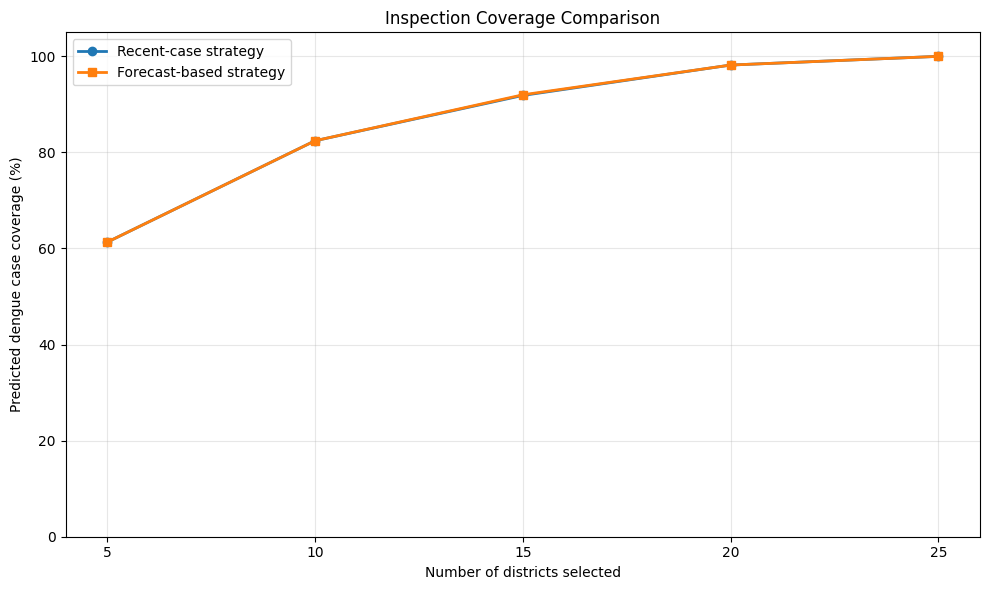

Chart saved: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\inspection_planning_evaluation\inspection_coverage_comparison.png


In [7]:
# ============================================================
# STEP 7 - VISUALISE INSPECTION COVERAGE
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    coverage_df["inspection_capacity"],
    coverage_df["recent_case_coverage_percent"],
    marker="o",
    linewidth=2,
    label="Recent-case strategy"
)

plt.plot(
    coverage_df["inspection_capacity"],
    coverage_df["forecast_coverage_percent"],
    marker="s",
    linewidth=2,
    label="Forecast-based strategy"
)

plt.xlabel("Number of districts selected")
plt.ylabel("Predicted dengue case coverage (%)")

plt.title("Inspection Coverage Comparison")

plt.xticks(inspection_capacities)
plt.ylim(0, 105)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

# Save chart
coverage_chart_path = (
    EVALUATION_DIR / "inspection_coverage_comparison.png"
)

plt.savefig(
    coverage_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", coverage_chart_path)

In [8]:
# ============================================================
# STEP 8 - COMPARE GEOGRAPHICAL ROUTE DISTANCES
# ============================================================

def calculate_nearest_neighbour_route(selected_districts, distance_matrix):
    """Calculate a nearest-neighbour route from Colombo."""

    remaining = set(selected_districts)

    start = "colombo"

    if start not in remaining:
        remaining.add(start)

    route = [start]
    remaining.remove(start)

    total_distance = 0.0
    current = start

    while remaining:
        next_district = min(
            remaining,
            key=lambda district: distance_matrix.loc[
                current, district
            ]
        )

        total_distance += distance_matrix.loc[
            current, next_district
        ]

        route.append(next_district)
        remaining.remove(next_district)
        current = next_district

    return route, total_distance


# Select the first 10 districts under each strategy
recent_top_10 = strategy_comparison.sort_values(
    "recent_case_rank"
).head(10)["district_key"].tolist()

forecast_top_10 = strategy_comparison.sort_values(
    "forecast_strategy_rank"
).head(10)["district_key"].tolist()


# Calculate routes
recent_route, recent_distance = calculate_nearest_neighbour_route(
    recent_top_10, distance_df
)

forecast_route, forecast_distance = calculate_nearest_neighbour_route(
    forecast_top_10, distance_df
)


# Display comparison
route_comparison_df = pd.DataFrame({
    "strategy": [
        "Recent-case strategy",
        "Forecast-based strategy"
    ],
    "districts_selected": [len(recent_top_10), len(forecast_top_10)],
    "estimated_haversine_distance_km": [
        recent_distance,
        forecast_distance
    ]
})

display(route_comparison_df.round(2))

print("Recent-case route:", " -> ".join(recent_route))
print("Forecast-based route:", " -> ".join(forecast_route))


# Save results
route_comparison_df.to_csv(
    EVALUATION_DIR / "strategy_route_distance_comparison.csv",
    index=False
)

print("\nRoute comparison saved.")

,strategy,districts_selected,estimated_haversine_distance_km
0,Recent-case strategy,10,813.12
1,Forecast-based strategy,10,813.12


Recent-case route: colombo -> gampaha -> kegalle -> kandy -> ratnapura -> matara -> galle -> kalutara -> hambantota -> jaffna
Forecast-based route: colombo -> gampaha -> kegalle -> kandy -> ratnapura -> matara -> galle -> kalutara -> hambantota -> jaffna

Route comparison saved.


In [9]:
# ============================================================
# STEP 9 - FINAL INSPECTION PLANNING EVALUATION SUMMARY
# ============================================================

summary = {
    "evaluation_period_start": forecast_df[
        "forecast_target_start"
    ].iloc[0],

    "evaluation_period_end": forecast_df[
        "forecast_target_end"
    ].iloc[0],

    "number_of_districts": len(strategy_comparison),

    "spearman_correlation": spearman_result.statistic,

    "kendall_correlation": kendall_result.statistic,

    "mean_absolute_rank_difference": mean_rank_difference,

    "maximum_absolute_rank_difference": maximum_rank_difference,

    "forecast_coverage_top_10_percent": coverage_df.loc[
        coverage_df["inspection_capacity"] == 10,
        "forecast_coverage_percent"
    ].iloc[0],

    "recent_case_coverage_top_10_percent": coverage_df.loc[
        coverage_df["inspection_capacity"] == 10,
        "recent_case_coverage_percent"
    ].iloc[0],

    "forecast_top_10_distance_km": forecast_distance,

    "recent_case_top_10_distance_km": recent_distance,

    "top_10_routes_identical": forecast_route == recent_route
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["metric", "value"]
)

display(summary_df)

# Save summary
summary_path = EVALUATION_DIR / "inspection_planning_evaluation_summary.csv"

summary_df.to_csv(summary_path, index=False)

print("\nFinal evaluation summary saved:")
print(summary_path)

,metric,value
0,evaluation_period_start,2025-12-20
1,evaluation_period_end,2025-12-26
2,number_of_districts,25
3,spearman_correlation,0.983077
4,kendall_correlation,0.906667
5,mean_absolute_rank_difference,0.96
6,maximum_absolute_rank_difference,3
7,forecast_coverage_top_10_percent,82.426593
8,recent_case_coverage_top_10_percent,82.426593
9,forecast_top_10_distance_km,813.120234



Final evaluation summary saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\inspection_planning_evaluation\inspection_planning_evaluation_summary.csv


In [10]:
# ============================================================
# STEP 10 - FINAL OUTPUT VALIDATION
# ============================================================

expected_outputs = [
    "inspection_strategy_comparison.csv",
    "ranking_agreement_metrics.csv",
    "inspection_coverage_evaluation.csv",
    "inspection_coverage_comparison.png",
    "strategy_route_distance_comparison.csv",
    "inspection_planning_evaluation_summary.csv"
]

print("FINAL OUTPUT VALIDATION")
print("=" * 55)

all_files_exist = True

for filename in expected_outputs:

    file_path = EVALUATION_DIR / filename
    exists = file_path.exists()

    print(f"{filename}: {'OK' if exists else 'MISSING'}")

    if not exists:
        all_files_exist = False

print("\n" + "=" * 55)

print("All expected outputs saved:", all_files_exist)

if all_files_exist:
    print("NOTEBOOK 14 OUTPUT VALIDATION PASSED")
else:
    print("Some outputs are missing. Please investigate.")

FINAL OUTPUT VALIDATION
inspection_strategy_comparison.csv: OK
ranking_agreement_metrics.csv: OK
inspection_coverage_evaluation.csv: OK
inspection_coverage_comparison.png: OK
strategy_route_distance_comparison.csv: OK
inspection_planning_evaluation_summary.csv: OK

All expected outputs saved: True
NOTEBOOK 14 OUTPUT VALIDATION PASSED
